In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
%matplotlib inline


def simulation_wrapper(state0, params, update, sim_time, dt): 
    #euler method to see behaviour quickly
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0] = state0
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt)
        
    return states[1:]


sim_time = 200
dt = 0.001

In [2]:
def model_equation(parameters, state_var, dt):
    #parmeters are: 
    #alpha, beta, and gamma (initation, elongation, degradation) rate and R (number of total ribosomes)
    
    #parameters is a dictionary with the different parameters 
    #we just read them out below to return the updated amounts of interactions
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes

    new_x_vec = x_vec + dt * (-α_dep_R(parameters['α'], r)  * r * x_vec  + parameters['β'] * xr_vec)
    new_xr_vec = xr_vec + dt * (α_dep_R(parameters['α'], r) * r * x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * (parameters['β'] * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


def α_dep_R(α, R): 
    #simplest proportional realtionship for now, we might have to normalise this or implement a ceiling
    
    return α * R

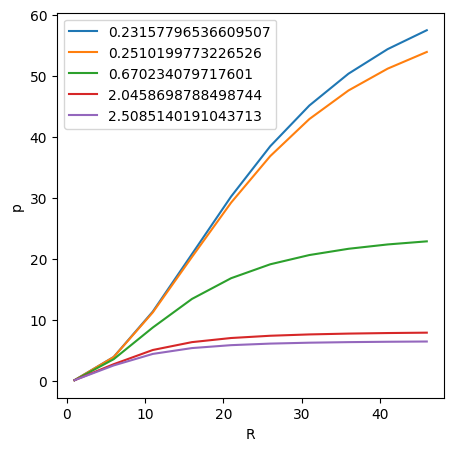

In [4]:
#mRNA is limiting: N < R

rng = np.random.RandomState(seed = 5)


#look at the relationship of R and x dependent on the length
N = 5 #number of genes/mRNA with differeng length

#we sample the length here, so we can compare all models directly without having to average
l_mean = 1 #mean of length of the genes
l_sd = 1.
l_alpha = (l_mean/l_sd)**2 # parameters for gamma distribution
l_theta = l_sd**2/l_mean # parameters for gamma distribution
l = np.sort(rng.gamma(l_alpha,scale = l_theta,size = N)) #length of the mRNA chain

α_mean = 0.05
# α_sd = 0.2
α_rand = rng.randn(N)

β_mean = 5
β_sd = β_mean
β_alpha = (β_mean/β_sd)**2 # parameters for gamma distribution
β_theta = β_sd**2/β_mean # parameters for gamma distribution
β_rand = rng.randn(N) 

γ_mean = .3
γ_sd = 0.0001
γ_rand = rng.randn(N)

# calculate parameters  
#α = α_mean + 0.001* α_rand #antiproportional
α = α_rand * 0 + 0.001 * np.mean(α_rand) + α_mean
β = β_mean / l + 0.001* β_rand  #(proportional, here anti-proportional because of equations) not taken into account yet... 
γ = γ_mean * 0 + np.mean(γ_mean) + np.mean(γ_sd)* np.mean(γ_rand)



parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['γ'] = γ
parameters['l'] = l

x0_mean = 1
x0_sd = 0.001
x0 = x0_mean + x0_sd*rng.randn(N)



Rs = np.arange(1,50,5)
results = np.zeros([Rs.shape[0],N])

for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]

    #init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
    init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

    baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
    results[r]= baseline[-1,2,:]
    

fig, ax = plt.subplots(1,1,figsize = (5,5))
for i in range(N):
    ax.plot(Rs, results[:,i], label = l[i])
ax.set_xlabel('R')
ax.set_ylabel('p')
ax.legend()
plt.show()

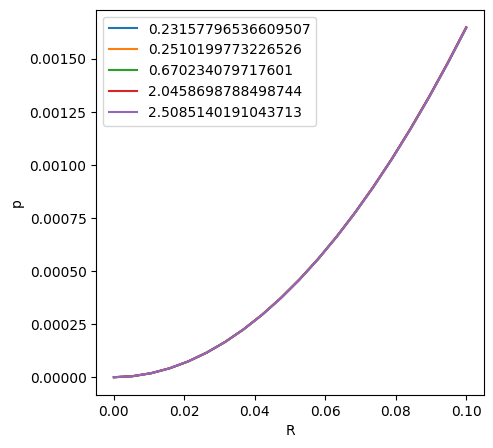

In [5]:
#mRNA is limiting: N > R

Rs = np.linspace(0.0001,.1,20)
results = np.zeros([Rs.shape[0],N])

for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]

    #init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
    init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

    baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
    results[r]= baseline[-1,2,:]
    

fig, ax = plt.subplots(1,1,figsize = (5,5))
for i in range(N):
    ax.plot(Rs, results[:,i], label = l[i])
ax.set_xlabel('R')
ax.set_ylabel('p')
ax.legend()
plt.show()